# Exploratory data analysis

These plots use the cleaned dataset. Genre counts include each genre attached to a movie.

In [8]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

data_path = "../data/cleaned_data.csv"
figure_dir = Path.cwd() / "../figures"
figure_dir.mkdir(exist_ok=True)
# Load the cleaned movie data
movies = pd.read_csv(data_path)
sns.set_theme(style="whitegrid")
print("Cleaned dataset shape:", movies.shape)
display(movies[["budget", "popularity", "revenue", "runtime", "vote_average", "vote_count"]].describe().T)

Cleaned dataset shape: (4803, 23)


,count,mean,std,min,25%,50%,75%,max
budget,4803.0,2.904504e+07,4.072239e+07,0.0,790000.00000,1.500000e+07,4.000000e+07,3.800000e+08
popularity,4803.0,2.149230e+01,3.181665e+01,0.0,4.66807,1.292159e+01,2.831350e+01,8.755813e+02
revenue,4803.0,8.226064e+07,1.628571e+08,0.0,0.00000,1.917000e+07,9.291719e+07,2.787965e+09
runtime,4801.0,1.068759e+02,2.261193e+01,0.0,94.00000,1.030000e+02,1.180000e+02,3.380000e+02
vote_average,4803.0,6.092172e+00,1.194612e+00,0.0,5.60000,6.200000e+00,6.800000e+00,1.000000e+01
vote_count,4803.0,6.902180e+02,1.234586e+03,0.0,54.00000,2.350000e+02,7.370000e+02,1.375200e+04


## Missing values after preprocessing

In [9]:
# Fill blank metadata fields when the cleaned CSV is reloaded
text_features = ["genres_text", "keywords_text", "overview", "tagline"]
movies[text_features] = movies[text_features].fillna("")

print("Missing values in recommendation text fields:")
display(movies[text_features].isna().sum().rename("missing values").to_frame())

print("Missing values in other retained fields:")
other_columns = [column for column in movies.columns if column not in text_features]
other_missing = movies[other_columns].isna().sum()
display(other_missing[other_missing > 0].rename("missing values").to_frame())

Missing values in recommendation text fields:


,missing values
genres_text,0
keywords_text,0
overview,0
tagline,0


Missing values in other retained fields:


,missing values
homepage,3091
release_date,1
runtime,2
release_year,1


## Which genres appear most often?

,movie count
genres_text,
Drama,2297
Comedy,1722
Thriller,1274
Action,1154
Romance,894
Adventure,790
Crime,696
Science Fiction,535
Horror,519


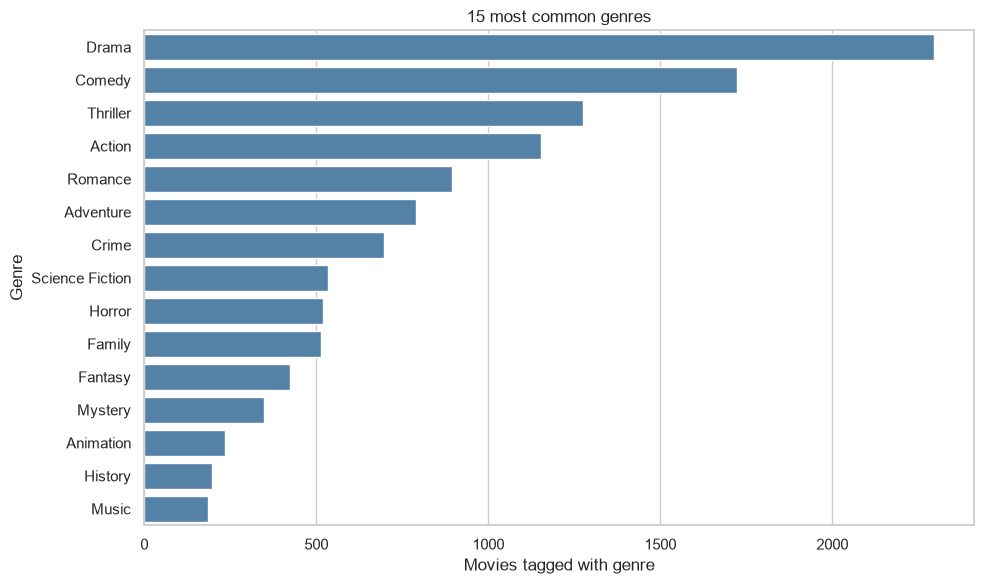

In [10]:
# Count each genre label across the movies
genre_counts = movies["genres_text"].fillna("").str.split("|").explode().str.strip()
genre_counts = genre_counts[genre_counts.ne("")].value_counts()
top_genres = genre_counts.head(15)
display(top_genres.rename("movie count").to_frame())

plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index, color="steelblue")
plt.title("15 most common genres")
plt.xlabel("Movies tagged with genre")
plt.ylabel("Genre")
plt.tight_layout()
plt.savefig(figure_dir / "top_genres.png", dpi=150)
plt.show()

The genre chart counts every label on a movie, so a movie with two genres contributes to both.

## How have release counts changed over time?

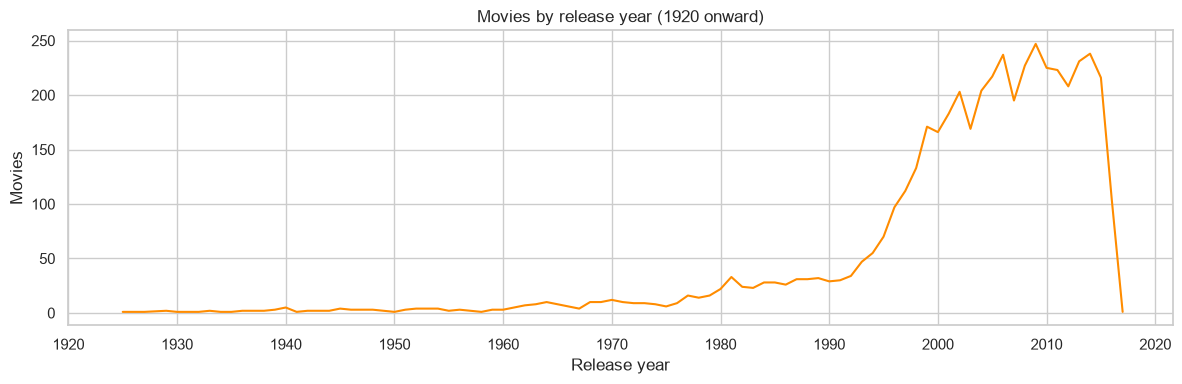

Release year range in the dataset: 1916 to 2017


In [11]:
# Count movies by release year
year_counts = movies["release_year"].dropna().astype(int).value_counts().sort_index()
year_counts = year_counts.loc[year_counts.index >= 1920]
plt.figure(figsize=(12, 4))
sns.lineplot(x=year_counts.index, y=year_counts.values, color="darkorange")
plt.title("Movies by release year (1920 onward)")
plt.xlabel("Release year")
plt.ylabel("Movies")
plt.xticks(range(1920, 2021, 10))
plt.tight_layout()
plt.savefig(figure_dir / "movies_by_year.png", dpi=150)
plt.show()
print("Release year range in the dataset:", int(movies["release_year"].min()), "to", int(movies["release_year"].max()))

## What do runtime and vote averages look like?

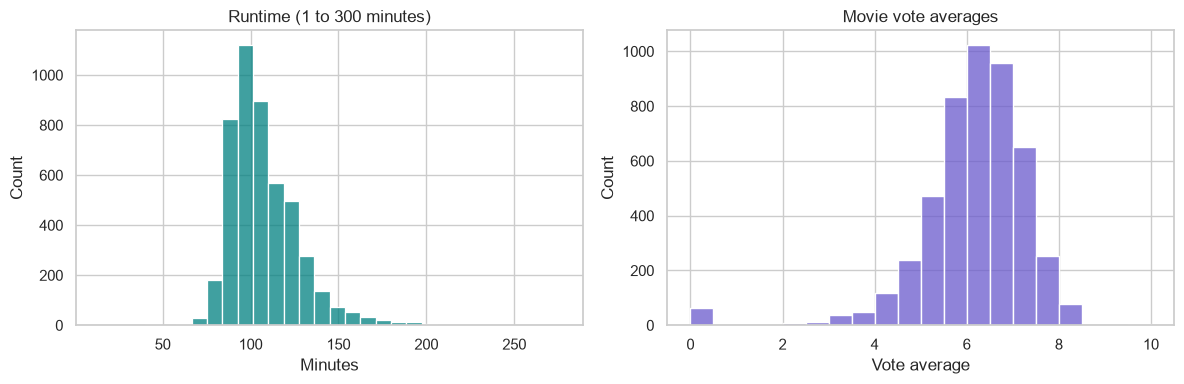

Movies with runtime between 1 and 300 minutes: 4765
Median runtime in that range: 104.0
Mean vote average: 6.09


In [12]:
# Keep the runtime plot focused on a readable range
valid_runtime = movies.loc[movies["runtime"].between(1, 300), "runtime"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(valid_runtime, bins=30, ax=axes[0], color="teal")
axes[0].set_title("Runtime (1 to 300 minutes)")
axes[0].set_xlabel("Minutes")
sns.histplot(movies["vote_average"].dropna(), bins=20, ax=axes[1], color="slateblue")
axes[1].set_title("Movie vote averages")
axes[1].set_xlabel("Vote average")
plt.tight_layout()
plt.savefig(figure_dir / "runtime_and_vote_average.png", dpi=150)
plt.show()
print("Movies with runtime between 1 and 300 minutes:", len(valid_runtime))
print("Median runtime in that range:", round(float(valid_runtime.median()), 1))
print("Mean vote average:", round(float(movies["vote_average"].mean()), 2))

## EDA notes

- Release dates span 1916 to 2017; a small number of dates and runtimes are missing.
- The source has aggregate vote averages and vote counts, which describe the catalog but do not provide user-specific feedback.
- Runtime is plotted between 1 and 300 minutes for readability; rows outside that plotting range remain in the cleaned data.